# Comparing and interrogating model performance

In [1]:
import json
import pandas as pd
import joblib
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

data_path = "../data"

with open(f"{data_path}/test_set.json", "r") as f:
    test_set = json.load(f)

In [2]:
# Ground truth from the fixed test set
comparison_df = pd.DataFrame({
    "Date": [quiz["date"] for quiz in test_set],
    "True answer": [quiz["answer"] for quiz in test_set]
})

# Standardised prediction files
model_files = {
    "TF-IDF + LR": "../data/predictions_tfidf_lr.csv",
    "MiniLM + LR": "../data/predictions_minilm_lr.csv",
    "MiniLM +  MLP": "../data/predictions_minilm_mlp.csv",
    "DistilBERT Headline": "../data/predictions_distilbert_headline.csv",
    "Distilbert Concat": "../data/predictions_distilbert_concat.csv",
    "Distilbert Shared": "../data/predictions_distilbert_shared.csv",
    "Llama QLoRA": "../data/predictions_llama_qlora.csv",
    "Claude Haiku 4.5": "../data/predictions_claude_haiku.csv",
    "GPT-5 Nano": "../data/predictions_gpt5_nano.csv",
    "Claude Fable 5.1": "../data/predictions_claude_fable.csv",
    "GPT-6 Astra": "../data/predictions_gpt6_astra.csv",
}

# Merge each model's results into the comparison dataframe
for model_name, filepath in model_files.items():
    model_df = pd.read_csv(filepath)

    model_df = model_df.rename(columns={
        "date": "Date",
        "prediction": f"{model_name} prediction",
        "confidence": f"{model_name} confidence",
    })

    comparison_df = comparison_df.merge(
        model_df,
        on="Date",
        how="left",
        validate="one_to_one",
    )

# Sort chronologically
comparison_df = comparison_df.sort_values("Date").reset_index(drop=True)

comparison_df

,Date,True answer,TF-IDF + LR prediction,TF-IDF + LR confidence,MiniLM + LR prediction,MiniLM + LR confidence,MiniLM + MLP prediction,MiniLM + MLP confidence,DistilBERT Headline prediction,DistilBERT Headline confidence,...,Llama QLoRA prediction,Llama QLoRA confidence,Claude Haiku 4.5 prediction,Claude Haiku 4.5 confidence,GPT-5 Nano prediction,GPT-5 Nano confidence,Claude Fable 5.1 prediction,Claude Fable 5.1 confidence,GPT-6 Astra prediction,GPT-6 Astra confidence
0,2019-11-23,0,3,0.338882,0,0.550084,0,0.405892,0,0.153801,...,1,0.648438,1,NaN,1,NaN,0,NaN,0,NaN
1,2020-01-18,3,3,0.280240,3,0.421458,3,0.351126,3,0.228968,...,3,0.667969,3,NaN,3,NaN,3,NaN,3,NaN
2,2020-02-22,0,2,0.405564,0,0.256603,0,0.368448,0,0.258610,...,3,0.792969,0,NaN,2,NaN,0,NaN,0,NaN
3,2020-03-28,1,2,0.361563,1,0.353343,1,0.313902,3,0.281819,...,1,0.695312,1,NaN,1,NaN,1,NaN,1,NaN
4,2020-05-09,1,1,0.369208,2,0.521405,2,0.396920,2,0.264420,...,2,0.585938,1,NaN,1,NaN,1,NaN,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62,2026-04-09,2,2,0.436148,2,0.477492,2,0.393201,2,0.161335,...,2,0.730469,0,NaN,0,NaN,2,NaN,2,NaN
63,2026-05-14,3,0,0.361564,2,0.256860,0,0.292179,3,0.260099,...,2,0.648438,3,NaN,3,NaN,3,NaN,3,NaN
64,2026-06-18,3,3,0.321707,3,0.407432,3,0.378150,3,0.126798,...,3,0.585938,0,NaN,0,NaN,3,NaN,1,NaN
65,2026-07-23,2,3,0.329653,2,0.369093,2,0.288379,3,0.201083,...,2,0.800781,3,NaN,3,NaN,3,NaN,3,NaN


In [3]:
prediction_cols = [
    "Date",
    "True answer",
    *[f"{model} prediction" for model in model_files]
]

display_df = comparison_df[prediction_cols].copy()

# Add accuracy row
accuracy_row = {"Date": "Test Accuracy", "True answer": ""}

for model in model_files:
    col = f"{model} prediction"
    accuracy = (comparison_df[col] == comparison_df["True answer"]).mean()
    accuracy_row[col] = f"{accuracy:.2%}"

display_df = pd.concat(
    [
        display_df,
        pd.DataFrame([accuracy_row])
    ],
    ignore_index=True
)


def colour_predictions(row):
    styles = []

    for col in display_df.columns:
        if col in ["Date", "True answer"] or row["Date"] == "Test Accuracy":
            styles.append("")
        else:
            correct = row[col] == row["True answer"]

            if correct:
                styles.append(
                    "background-color: #1B5E20; color: white; font-weight: bold;"
                )
            else:
                styles.append(
                    "background-color: #8B1E1E; color: white; font-weight: bold;"
                )

    return styles


styled_df = (
    display_df.style
    .apply(colour_predictions, axis=1)
    .set_properties(**{"text-align": "center"})
    .set_properties(
        subset=pd.IndexSlice[display_df.index[-1], :],
        **{"font-weight": "bold"}
    )
    .hide(axis="index")
)

styled_df

Date,True answer,TF-IDF + LR prediction,MiniLM + LR prediction,MiniLM + MLP prediction,DistilBERT Headline prediction,Distilbert Concat prediction,Distilbert Shared prediction,Llama QLoRA prediction,Claude Haiku 4.5 prediction,GPT-5 Nano prediction,Claude Fable 5.1 prediction,GPT-6 Astra prediction
2019-11-23,0,3,0,0,0,0,0,1,1,1,0,0
2020-01-18,3,3,3,3,3,0,3,3,3,3,3,3
2020-02-22,0,2,0,0,0,0,0,3,0,2,0,0
2020-03-28,1,2,1,1,3,0,3,1,1,1,1,1
2020-05-09,1,1,2,2,2,0,2,2,1,1,1,1
2020-06-13,0,1,1,1,1,0,1,1,1,2,3,3
2020-07-25,1,1,2,2,1,0,1,2,0,1,1,1
2020-08-29,2,3,2,2,3,3,0,0,2,1,2,2
2020-10-03,3,3,2,0,0,0,3,1,1,3,3,3
2020-11-05,1,3,2,2,3,0,3,1,3,3,1,1


Correct models,Quiz dates,Quiz Count
11,2022-12-22,1
10,2020-01-18 2021-04-15 2021-11-11,3
9,2023-02-09 2023-08-10 2023-09-14 2023-11-30 2024-07-11,5
8,2020-02-22 2021-09-02 2021-12-23 2022-05-19 2022-11-10 2024-03-21 2024-05-30 2025-03-27 2026-04-09,9
7,2019-11-23 2020-03-28 2021-07-29 2022-01-27 2022-03-03 2023-03-16 2023-06-01 2024-09-19 2025-06-05 2025-07-17 2025-10-30 2025-12-11 2026-06-18,13
6,2020-07-25 2022-07-28 2024-04-25 2025-01-16 2025-05-01 2025-09-25,6
5,2020-05-09 2020-08-29 2020-10-03 2021-06-24 2021-10-07 2022-04-14 2022-10-06 2023-07-06 2024-02-15 2026-05-14,10
4,2021-02-04 2021-03-11 2021-05-20 2022-06-23 2023-10-19 2024-01-11 2024-10-24 2024-12-05 2026-01-29,9
3,2020-11-05 2020-12-17 2022-09-01 2024-08-15 2026-07-23,5
2,2023-04-27 2025-02-20 2025-08-21,3


<Axes: xlabel='Number of Models Correct', ylabel='Number of Quizzes'>

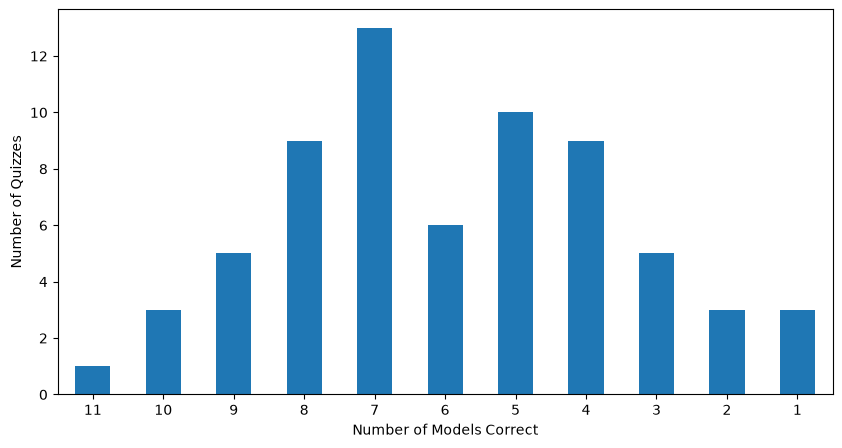

In [4]:
# Count correct predictions for each quiz
correct_counts = (
    comparison_df[prediction_cols[2:]]
    .eq(comparison_df["True answer"], axis=0)
    .sum(axis=1)
)

# Group quiz dates by number of correct predictions
quiz_agreement_df = (
    pd.DataFrame({
        "Correct models": correct_counts,
        "Quiz dates": comparison_df["Date"]
    })
    .groupby("Correct models")["Quiz dates"]
    .agg(lambda dates: "\n".join(dates))
    .reset_index()
    .sort_values("Correct models", ascending=False)
)

quiz_agreement_df["Quiz Count"] = (
    quiz_agreement_df["Correct models"]
    .map(correct_counts.value_counts())
    .fillna(0)
    .astype(int)
)

display(
    quiz_agreement_df.style
    .set_properties(subset=["Quiz dates"], **{"white-space": "pre-wrap"})
    .hide(axis="index")
)

quiz_agreement_df.plot(
    x="Correct models",
    y="Quiz Count",
    kind="bar",
    legend=False,
    xlabel="Number of Models Correct",
    ylabel="Number of Quizzes",
    rot=0,
    figsize=(10, 5),
)

In [5]:
import html
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Look up the original quiz data by date
quiz_by_date = {str(quiz["date"]): quiz for quiz in test_set}

model_prediction_cols = [
    f"{model} prediction" for model in model_files
]

# Count correct model predictions for each quiz
correct_counts_by_date = dict(zip(
    comparison_df["Date"].astype(str),
    comparison_df[model_prediction_cols]
        .eq(comparison_df["True answer"], axis=0)
        .sum(axis=1)
        .astype(int)
))

# Dropdown labels show the date and how many models were correct
quiz_options = [
    (
        f"{date} — {correct_counts_by_date[date]}/{len(model_files)} models correct",
        date,
    )
    for date in comparison_df["Date"].astype(str)
]

quiz_selector = widgets.Dropdown(
    options=quiz_options,
    description="Quiz:",
    layout=widgets.Layout(width="550px"),
    style={"description_width": "60px"},
)

quiz_output = widgets.Output()


def show_quiz(change=None):
    date = quiz_selector.value
    quiz = quiz_by_date[date]
    true_answer = int(quiz["answer"])

    row = comparison_df.loc[
        comparison_df["Date"].astype(str) == date
    ].iloc[0]

    with quiz_output:
        clear_output(wait=True)

        # Quiz summary
        display(HTML(
            f"""
            <h3>{html.escape(date)}</h3>
            <p>
                <b>Models correct:</b>
                {correct_counts_by_date[date]} / {len(model_files)}
                &nbsp; | &nbsp;
                <b>True answer index:</b> {true_answer}
            </p>
            <p style="color: #888;">
                Headline indices are zero-based (0–3).
                The green headline is the ground-truth fake.
            </p>
            """
        ))

        # Display the four headlines, highlighting the fake one
        headline_cards = []

        for index, headline in enumerate(quiz["headlines"]):
            is_fake = index == true_answer

            if is_fake:
                background = "#575E1B"
                colour = "#FFFFFF"
                label = f"Headline index {index} - LIE"
            else:
                background = "#F1F5F9"
                colour = "#172033"
                label = f"Headline index {index} - REAL"

            headline_cards.append(
                f"""
                <div style="
                    background: {background};
                    color: {colour};
                    padding: 12px 16px;
                    margin: 8px 0;
                    border-radius: 6px;
                    line-height: 1.5;
                ">
                    <div style="
                        font-size: 12px;
                        font-weight: bold;
                        margin-bottom: 4px;
                    ">{label}</div>
                    {html.escape(str(headline))}
                </div>
                """
            )

        display(HTML("".join(headline_cards)))

        # Model predictions and confidence scores
        results = []

        for model_name in model_files:
            prediction = row[f"{model_name} prediction"]
            confidence = row.get(f"{model_name} confidence", np.nan)

            if pd.isna(prediction):
                prediction_display = "—"
                outcome = "Missing"
            else:
                prediction_display = int(prediction)
                outcome = (
                    "Correct"
                    if prediction_display == true_answer
                    else "Incorrect"
                )

            if pd.notna(confidence):
                confidence_display = f"{float(confidence):.3f}"
            else:
                confidence_display = "—"

            results.append({
                "Model": model_name,
                "Prediction index": prediction_display,
                "Saved confidence": confidence_display,
                "Outcome": outcome,
            })

        results_df = pd.DataFrame(results)

        def style_results(result_row):
            if result_row["Outcome"] == "Correct":
                colour = "#1B5E20"
            elif result_row["Outcome"] == "Incorrect":
                colour = "#8B1E1E"
            else:
                colour = "#555555"

            return [
                "",
                f"background-color: {colour}; color: white; font-weight: bold;",
                "",
                f"background-color: {colour}; color: white; font-weight: bold;",
            ]

        display(
            results_df.style
            .apply(style_results, axis=1)
            .hide(axis="index")
            .set_properties(**{"text-align": "left"})
        )


# Render the interactive interface
quiz_selector.observe(show_quiz, names="value")

display(widgets.VBox([
    quiz_selector,
    quiz_output,
]))

show_quiz()

### Classification reports and confusion matrices

In [6]:
from sklearn.metrics import classification_report

y_true = comparison_df["True answer"].astype(int)

for model_name in model_files:
    y_pred = comparison_df[f"{model_name} prediction"].astype(int)

    print(f"\n{'=' * 70}")
    print(model_name)
    print("=" * 70)

    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=["Position 0", "Position 1", "Position 2", "Position 3"],
        digits=3,
        zero_division=0,
    ))


TF-IDF + LR
              precision    recall  f1-score   support

  Position 0      0.438     0.412     0.424        17
  Position 1      0.583     0.389     0.467        18
  Position 2      0.400     0.462     0.429        13
  Position 3      0.375     0.474     0.419        19

    accuracy                          0.433        67
   macro avg      0.449     0.434     0.435        67
weighted avg      0.452     0.433     0.435        67


MiniLM + LR
              precision    recall  f1-score   support

  Position 0      0.545     0.706     0.615        17
  Position 1      0.400     0.222     0.286        18
  Position 2      0.312     0.385     0.345        13
  Position 3      0.526     0.526     0.526        19

    accuracy                          0.463        67
   macro avg      0.446     0.460     0.443        67
weighted avg      0.456     0.463     0.449        67


MiniLM +  MLP
              precision    recall  f1-score   support

  Position 0      0.529     0.529 

In [9]:
from sklearn.metrics import confusion_matrix
from IPython.display import display, Markdown

y_true = comparison_df["True answer"].astype(int)

for model_name in model_files:
    y_pred = comparison_df[f"{model_name} prediction"].astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

    print(f"\n{model_name}")
    display(pd.DataFrame(
        cm,
        index=pd.Index([0, 1, 2, 3], name="True rows \\ Predicted cols"),
        columns=[0, 1, 2, 3],
    ))


TF-IDF + LR


,0,1,2,3
True rows \ Predicted cols,,,,
0,7,2,4,4
1,4,7,1,6
2,1,1,6,5
3,4,2,4,9



MiniLM + LR


,0,1,2,3
True rows \ Predicted cols,,,,
0,12,2,1,2
1,4,4,5,5
2,3,3,5,2
3,3,1,5,10



MiniLM +  MLP


...

,0,1,2,3
True rows \ Predicted cols,,,,
0,3,7,6,1
1,1,10,5,2
2,5,3,3,2
3,5,1,3,10



Claude Fable 5.1


,0,1,2,3
True rows \ Predicted cols,,,,
0,14,1,0,2
1,1,16,0,1
2,0,0,12,1
3,1,1,0,17



GPT-6 Astra


,0,1,2,3
True rows \ Predicted cols,,,,
0,15,1,0,1
1,0,16,0,2
2,1,0,11,1
3,1,1,0,17


In [17]:
from sklearn.metrics import roc_auc_score

confidence_results = []

for model_name in [
    "TF-IDF + LR",
    "MiniLM + LR",
    "MiniLM +  MLP",
    "DistilBERT Headline",
    "Distilbert Concat",
    "Distilbert Shared",
    "Llama QLoRA",
]:
    prediction_col = f"{model_name} prediction"
    confidence_col = f"{model_name} confidence"

    # Identify correct and incorrect predictions
    correct = comparison_df[prediction_col] == comparison_df["True answer"]
    confidence = comparison_df[confidence_col]

    # Mean confidence for correct and incorrect predictions
    mean_correct = confidence[correct].mean()
    mean_incorrect = confidence[~correct].mean()

    # ROC AUC: how well confidence distinguishes correct from incorrect
    # 1 = perfect discrimination; 0.5 = no discrimination
    correctness = correct.astype(int)
    roc_auc = roc_auc_score(correctness, confidence)

    confidence_results.append({
        "Model": model_name,
        "Mean confidence (correct)": mean_correct,
        "Mean confidence (incorrect)": mean_incorrect,
        "Difference (percentage points)": (
            mean_correct - mean_incorrect
        ) * 100,
        "ROC AUC": roc_auc,
    })

confidence_results_df = pd.DataFrame(confidence_results)

# Format the results for display
confidence_results_df.style.format({
    "Mean confidence (correct)": "{:.2%}",
    "Mean confidence (incorrect)": "{:.2%}",
    "Difference (percentage points)": "{:+.2f}",
    "ROC AUC": "{:.3f}",
}).hide(axis="index")

Model,Mean confidence (correct),Mean confidence (incorrect),Difference (percentage points),ROC AUC
TF-IDF + LR,36.92%,33.71%,+3.21,0.585
MiniLM + LR,42.94%,35.48%,+7.46,0.692
MiniLM + MLP,36.45%,31.74%,+4.71,0.684
DistilBERT Headline,25.61%,21.55%,+4.06,0.651
Distilbert Concat,37.99%,41.44%,-3.45,0.389
Distilbert Shared,49.24%,44.80%,+4.43,0.642
Llama QLoRA,62.60%,56.05%,+6.55,0.636


,Model,N,ECE,ECE (%)
0,MiniLM + LR,67,0.073,7.3
1,TF-IDF + LR,67,0.082,8.2
2,DistilBERT Shared,67,0.087,8.7
3,Llama QLoRA,67,0.105,10.5
4,MiniLM + MLP,67,0.124,12.4
5,DistilBERT Concat,67,0.142,14.2
6,DistilBERT Headline,67,0.243,24.3



TF-IDF + LR — ECE: 0.082


,Confidence bin,N,Mean confidence,Observed accuracy
bin,,,,
0,0%–20%,NaN,NaN,NaN
1,20%–40%,51,0.320,0.373
2,40%–60%,16,0.451,0.625
3,60%–80%,NaN,NaN,NaN
4,80%–100%,NaN,NaN,NaN



MiniLM + LR — ECE: 0.073


,Confidence bin,N,Mean confidence,Observed accuracy
bin,,,,
0,0%–20%,3,0.160,0.333
1,20%–40%,33,0.317,0.333
2,40%–60%,30,0.484,0.600
3,60%–80%,1,0.610,1.000
4,80%–100%,NaN,NaN,NaN


...

,Confidence bin,N,Mean confidence,Observed accuracy
bin,,,,
0,0%–20%,NaN,NaN,NaN
1,20%–40%,35,0.351,0.371
2,40%–60%,30,0.451,0.200
3,60%–80%,2,0.640,0.000
4,80%–100%,NaN,NaN,NaN



DistilBERT Shared — ECE: 0.087


,Confidence bin,N,Mean confidence,Observed accuracy
bin,,,,
0,0%–20%,NaN,NaN,NaN
1,20%–40%,17,0.345,0.294
2,40%–60%,42,0.484,0.571
3,60%–80%,8,0.662,0.500
4,80%–100%,NaN,NaN,NaN



Llama QLoRA — ECE: 0.105


,Confidence bin,N,Mean confidence,Observed accuracy
bin,,,,
0,0%–20%,NaN,NaN,NaN
1,20%–40%,5,0.353,0.600
2,40%–60%,32,0.512,0.344
3,60%–80%,24,0.695,0.708
4,80%–100%,6,0.845,0.833


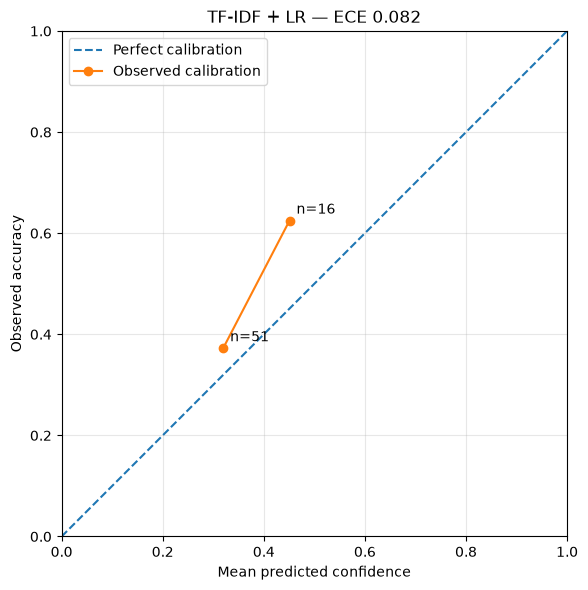

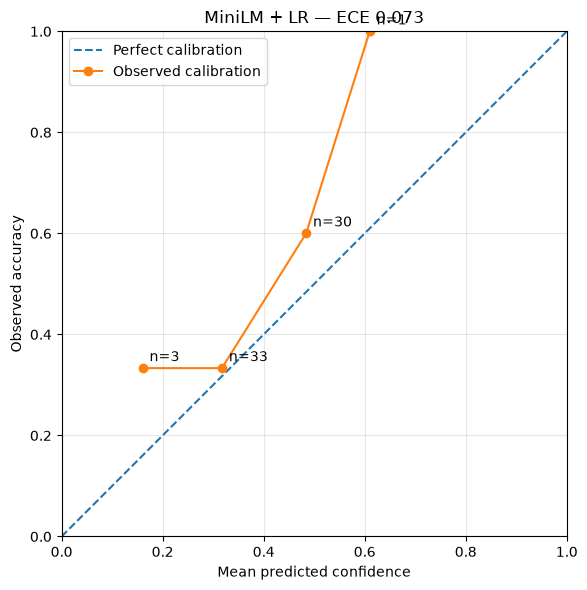

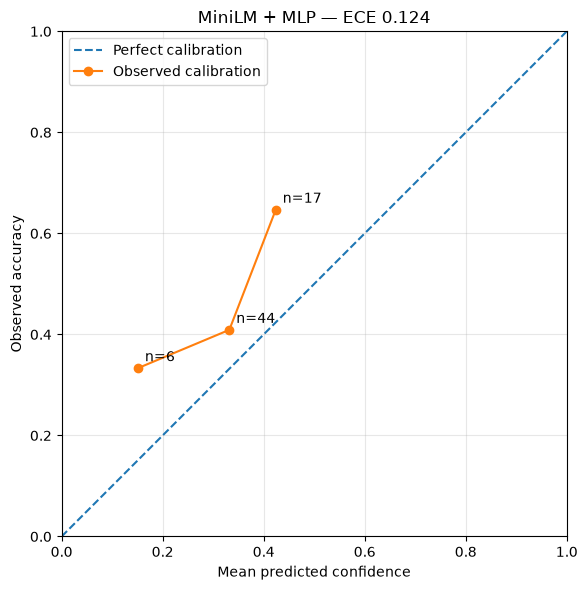

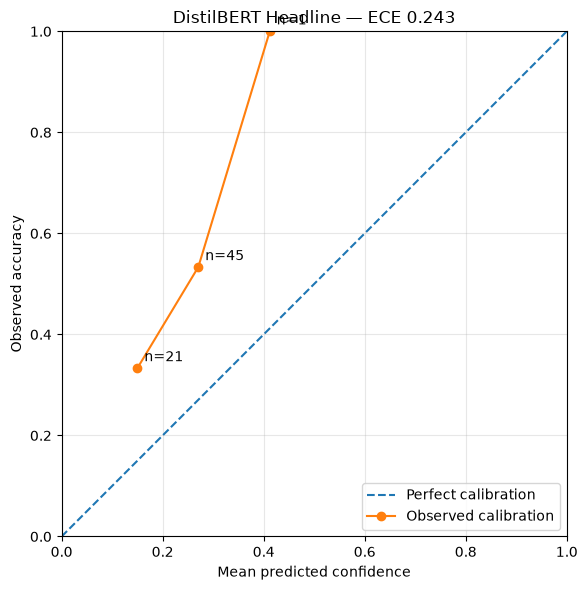

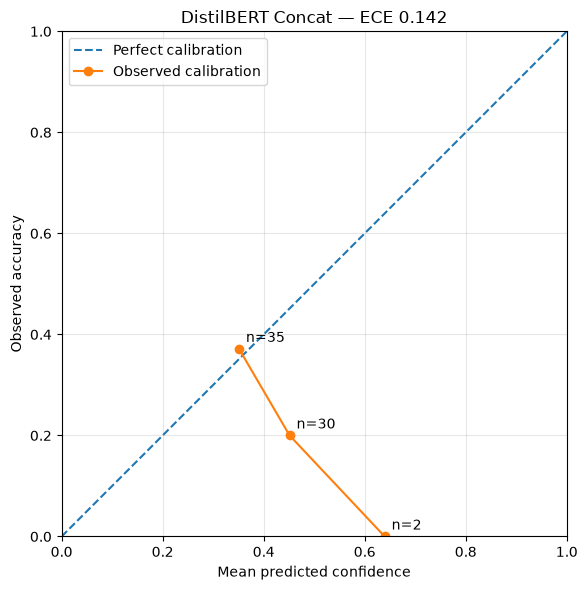

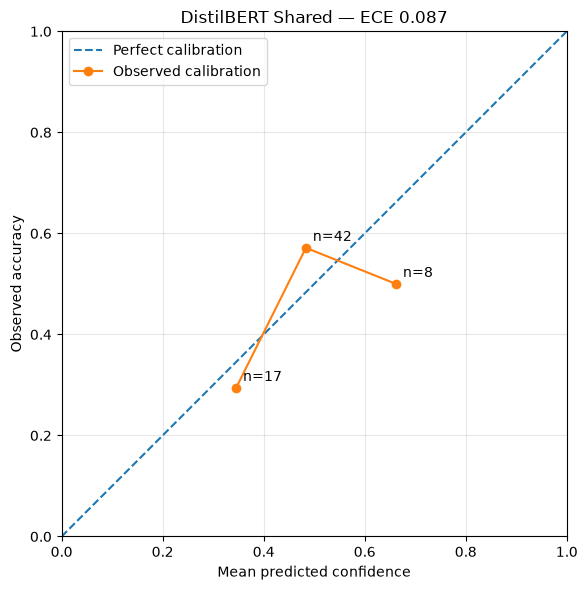

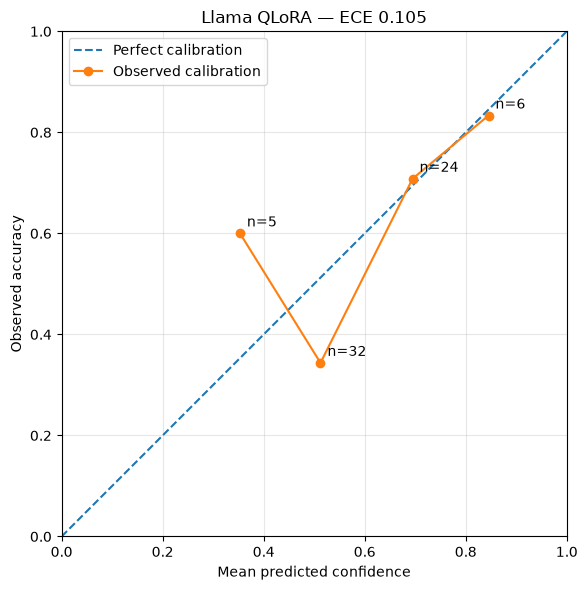

In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Update these names to match your existing DataFrame.

df = comparison_df
TRUE_COL = "True answer"

MODELS = {
    "TF-IDF + LR": {
        "prediction": "TF-IDF + LR prediction",
        "confidence": "TF-IDF + LR confidence",
    },
    "MiniLM + LR": {
        "prediction": "MiniLM + LR prediction",
        "confidence": "MiniLM + LR confidence",
    },
    "MiniLM + MLP": {
        "prediction": "MiniLM +  MLP prediction",
        "confidence": "MiniLM +  MLP confidence",
    },
    "DistilBERT Headline": {
        "prediction": "DistilBERT Headline prediction",
        "confidence": "DistilBERT Headline confidence",
    },
    "DistilBERT Concat": {
        "prediction": "Distilbert Concat prediction",
        "confidence": "Distilbert Concat confidence",
    },
    "DistilBERT Shared": {
        "prediction": "Distilbert Shared prediction",
        "confidence": "Distilbert Shared confidence",
    },
    "Llama QLoRA": {
        "prediction": "Llama QLoRA prediction",
        "confidence": "Llama QLoRA confidence",
    },
}

# Five fixed-width bins: [0, 0.2), ..., [0.8, 1.0].
BIN_EDGES = np.linspace(0, 1, 6)


def calculate_calibration(data, prediction_col, confidence_col):
    """Calculate bin-level calibration metrics and aggregate ECE."""

    results = data[[TRUE_COL, prediction_col, confidence_col]].copy()
    results = results.dropna()

    results["correct"] = (
        results[prediction_col] == results[TRUE_COL]
    ).astype(int)

    # Accommodate confidence stored as either fractions or percentages.
    confidence = results[confidence_col].astype(float)
    if confidence.max() > 1:
        confidence = confidence / 100

    if not confidence.between(0, 1).all():
        raise ValueError(
            f"Confidence values in {confidence_col} must be between 0 and 1 "
            "or between 0 and 100."
        )

    results["confidence"] = confidence

    # Include confidence == 1.0 in the final bin.
    results["bin"] = pd.cut(
        results["confidence"],
        bins=BIN_EDGES,
        labels=False,
        include_lowest=True,
        right=False,
    )
    results["bin"] = results["bin"].fillna(4).astype(int)

    bins = (
        results.groupby("bin", observed=True)
        .agg(
            count=("correct", "size"),
            mean_confidence=("confidence", "mean"),
            accuracy=("correct", "mean"),
        )
        .reindex(range(len(BIN_EDGES) - 1))
    )

    bins["gap"] = (
        bins["accuracy"] - bins["mean_confidence"]
    ).abs()

    n = len(results)
    ece = (
        (bins["count"] / n) * bins["gap"]
    ).sum()

    # Empty bins have no observed confidence or accuracy.
    bins["bin_range"] = [
        f"{BIN_EDGES[i]:.0%}–{BIN_EDGES[i + 1]:.0%}"
        for i in range(len(BIN_EDGES) - 1)
    ]

    return results, bins, ece


# Calculate metrics for every model.
calibration_results = {}
summary_rows = []

for model_name, columns in MODELS.items():
    predictions, bins, ece = calculate_calibration(
        df,
        columns["prediction"],
        columns["confidence"],
    )

    calibration_results[model_name] = {
        "predictions": predictions,
        "bins": bins,
        "ece": ece,
    }

    summary_rows.append({
        "Model": model_name,
        "N": len(predictions),
        "ECE": ece,
        "ECE (%)": 100 * ece,
    })

ece_summary = (
    pd.DataFrame(summary_rows)
    .sort_values("ECE")
    .reset_index(drop=True)
)

display(ece_summary.round({"ECE": 3, "ECE (%)": 1}))


# Display the bin-level values for inspection.
for model_name, result in calibration_results.items():
    print(f"\n{model_name} — ECE: {result['ece']:.3f}")
    table = result["bins"][
        ["bin_range", "count", "mean_confidence", "accuracy"]
    ].rename(columns={
        "bin_range": "Confidence bin",
        "count": "N",
        "mean_confidence": "Mean confidence",
        "accuracy": "Observed accuracy",
    }).round({
        "Mean confidence": 3,
        "Observed accuracy": 3,
    })

    table["N"] = table["N"].map(
        lambda x: f"{x:.0f}" if pd.notna(x) else "NaN"
    )

    display(table)


# Plot one reliability diagram per model.
for model_name, result in calibration_results.items():
    bins = result["bins"]
    populated = bins["count"] > 0

    fig, ax = plt.subplots(figsize=(6, 6))

    # Perfect calibration reference.
    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        label="Perfect calibration",
    )

    ax.plot(
        bins.loc[populated, "mean_confidence"],
        bins.loc[populated, "accuracy"],
        marker="o",
        linestyle="-",
        label="Observed calibration",
    )

    # Label each point with the number of predictions in its bin.
    for _, row in bins.loc[populated].iterrows():
        ax.annotate(
            f"n={int(row['count'])}",
            (row["mean_confidence"], row["accuracy"]),
            xytext=(5, 5),
            textcoords="offset points",
        )

    ax.set(
        xlim=(0, 1),
        ylim=(0, 1),
        xlabel="Mean predicted confidence",
        ylabel="Observed accuracy",
        title=f"{model_name} — ECE {result['ece']:.3f}",
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()
